# 01 - Tournaments and matches
What the dataset contains, how matches are decided and what has changed edition by edition. Source: gold layer (`cricket_gold.duckdb`).

In [1]:
import duckdb, pandas as pd, numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
con = duckdb.connect(str(ROOT / "data" / "warehouse" / "cricket_gold.duckdb"), read_only=True)
q = lambda sql: con.execute(sql).fetchdf()
FMT = {"ODI": "#2a6fbb", "T20": "#e07b00"}   # one colour per format, used everywhere
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "figure.figsize": (9, 4.2)})
pd.set_option("display.width", 160)

## Coverage: what data exists for each edition

             tournament_name format  year  played_matches  played_with_ball_by_ball  standings_rows  teams  teams_with_squad
  ICC Cricket World Cup 2003    ODI  2003              50                        47              20     14                14
  ICC Cricket World Cup 2007    ODI  2007              51                        50              24     16                16
  ICC Cricket World Cup 2011    ODI  2011              48                        48              14     14                14
  ICC Cricket World Cup 2015    ODI  2015              48                        42              14     14                14
  ICC Cricket World Cup 2019    ODI  2019              44                        35              10     10                10
  ICC Cricket World Cup 2023    ODI  2023              48                        39              10     10                10
     ICC World Twenty20 2007    T20  2007              26                         0              20     12                12


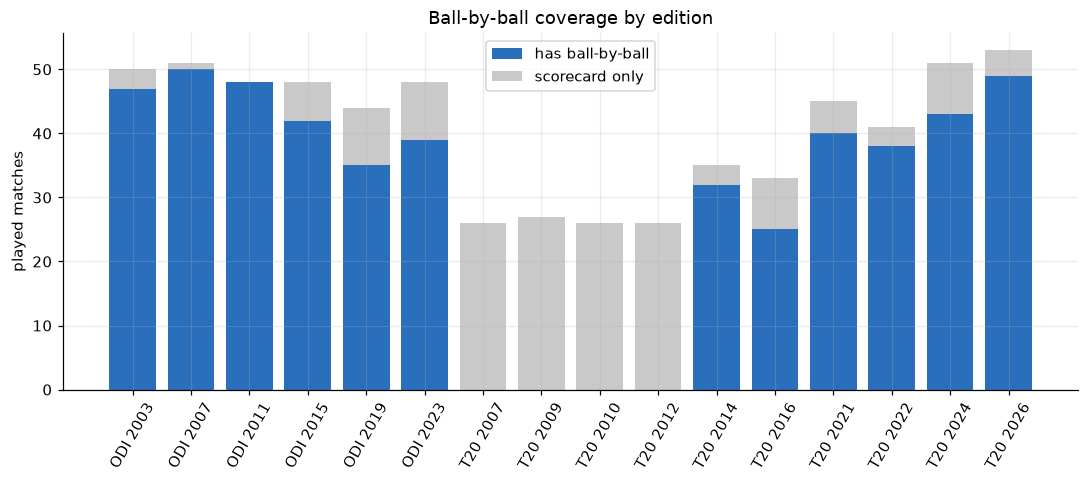

FINDING: 488 of 652 played matches (75%) have ball-by-ball data; the rest are scorecard-only (source limit).


In [2]:
cov = q("select tournament_name, format, year, played_matches, played_with_ball_by_ball, standings_rows, teams, teams_with_squad from gold.mart_data_coverage order by format, year")
print(cov.to_string(index=False))
fig, ax = plt.subplots(figsize=(10, 4.5))
lab = cov["format"] + " " + cov["year"].astype(str)
ax.bar(lab, cov["played_with_ball_by_ball"], color="#2a6fbb", label="has ball-by-ball")
ax.bar(lab, cov["played_matches"] - cov["played_with_ball_by_ball"], bottom=cov["played_with_ball_by_ball"], color="#c9c9c9", label="scorecard only")
ax.set_ylabel("played matches"); ax.set_title("Ball-by-ball coverage by edition"); ax.legend(); plt.xticks(rotation=60)
plt.tight_layout(); plt.show()
tot, bbb = cov.played_matches.sum(), cov.played_with_ball_by_ball.sum()
print(f"FINDING: {bbb} of {tot} played matches ({100*bbb/tot:.0f}%) have ball-by-ball data; the rest are scorecard-only (source limit).")

## How matches end

format     ODI  T20
outcome            
abandoned    4   10
no_result    4    5
runs       155  186
tie          4    6
walkover     2    0
wickets    130  171


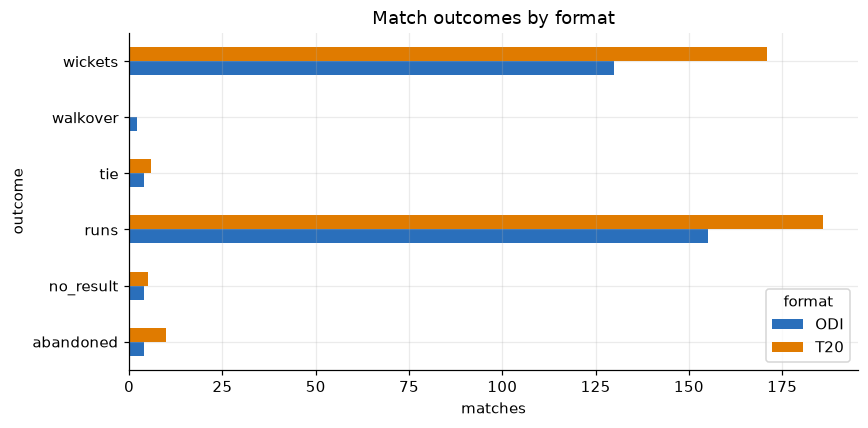

In [3]:
res = q("select format, coalesce(margin_type,'unknown') as outcome, count(*) n from gold.fact_matches group by 1,2 order by 1,3 desc")
piv = res.pivot(index="outcome", columns="format", values="n").fillna(0).astype(int)
print(piv)
piv.plot.barh(color=[FMT["ODI"], FMT["T20"]], figsize=(8, 4)); plt.title("Match outcomes by format"); plt.xlabel("matches"); plt.tight_layout(); plt.show()

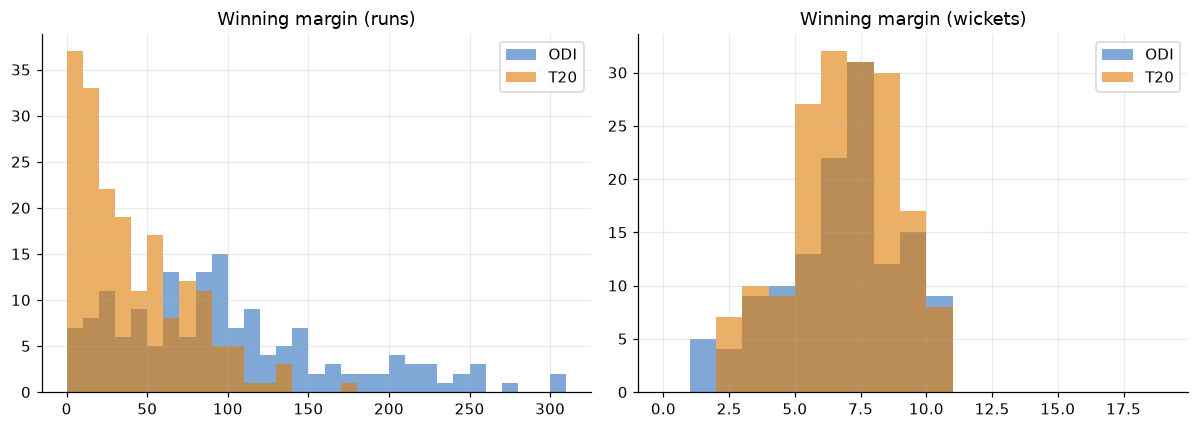

FINDING: median winning margin = {('ODI', 'runs'): 89.0, ('ODI', 'wickets'): 7.0, ('T20', 'runs'): 30.5, ('T20', 'wickets'): 7.0}


In [4]:
m = q("select format, margin_type, margin_value from gold.fact_matches where margin_type in ('runs','wickets')")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, kind in zip(axes, ["runs", "wickets"]):
    for f, g in m[m.margin_type == kind].groupby("format"):
        ax.hist(g.margin_value, bins=range(0, int(m[m.margin_type == kind].margin_value.max()) + 10, 10 if kind == "runs" else 1), alpha=.6, label=f, color=FMT[f])
    ax.set_title(f"Winning margin ({kind})"); ax.legend()
plt.tight_layout(); plt.show()
med = m.groupby(["format", "margin_type"]).margin_value.median()
print("FINDING: median winning margin =", med.round(1).to_dict())

## Batting first vs chasing, and the toss

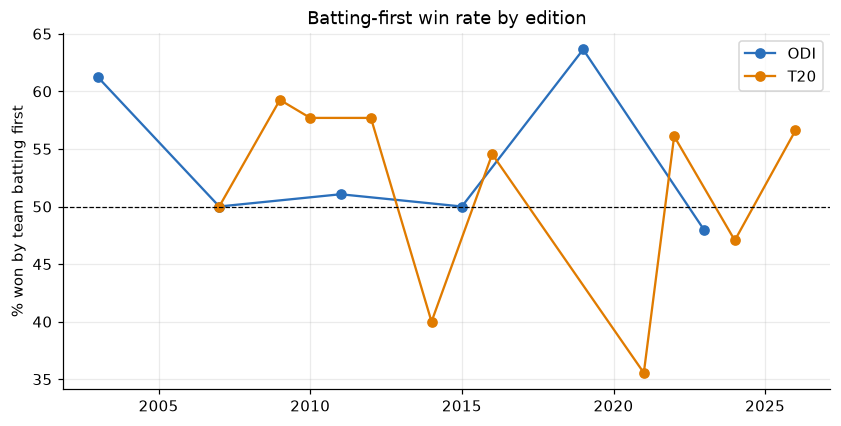

FINDING: overall bat-first win rate = {'ODI': 53.8, 'T20': 50.7} (see statistical_tests.md: not distinguishable from 50%)


In [5]:
d = q("""select format, year, count(*) n,
  avg(case when winner_id = batting_first_team_id then 1.0 else 0 end) bat_first_win
  from gold.fact_matches where is_completed and not is_walkover and winner_id is not null group by 1,2 order by 1,2""")
fig, ax = plt.subplots()
for f, g in d.groupby("format"):
    ax.plot(g.year, 100 * g.bat_first_win, "o-", color=FMT[f], label=f)
ax.axhline(50, color="k", lw=.8, ls="--"); ax.set_ylabel("% won by team batting first"); ax.set_title("Batting-first win rate by edition"); ax.legend()
plt.show()
allr = d.assign(w=d.bat_first_win * d.n).groupby("format").apply(lambda g: g.w.sum() / g.n.sum(), include_groups=False)
print("FINDING: overall bat-first win rate =", (100 * allr).round(1).to_dict(), "(see statistical_tests.md: not distinguishable from 50%)")

toss_decision  bat  field
format                   
ODI            151    142
T20            141    228


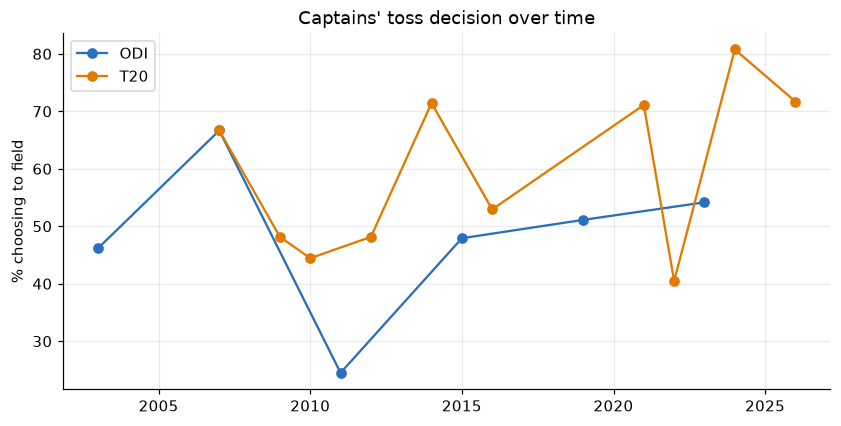

In [6]:
t = q("""select format, toss_decision, count(*) n from gold.fact_matches where toss_decision is not null group by 1,2""")
print(t.pivot(index="format", columns="toss_decision", values="n"))
y = q("""select year, format, avg(case when toss_decision='field' then 1.0 else 0 end)*100 as field_pct from gold.fact_matches where toss_decision is not null group by 1,2 order by 2,1""")
fig, ax = plt.subplots()
for f, g in y.groupby("format"):
    ax.plot(g.year, g.field_pct, "o-", color=FMT[f], label=f)
ax.set_ylabel("% choosing to field"); ax.set_title("Captains' toss decision over time"); ax.legend(); plt.show()

## Scoring and boundaries over time

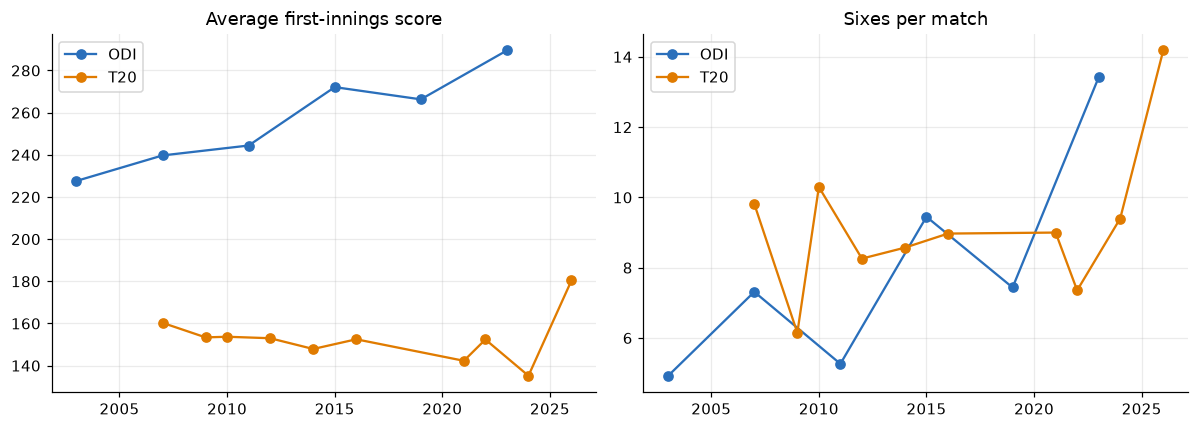

FINDING [ODI]: avg first-innings score 228 (2003) -> 290 (2023); sixes/match 4.9 -> 13.4
FINDING [T20]: avg first-innings score 160 (2007) -> 180 (2026); sixes/match 9.8 -> 14.2


In [7]:
s = q("select format, year, runs_per_match, avg_first_innings_score, sixes, matches from gold.mart_tournament_summary order by 1,2")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for f, g in s.groupby("format"):
    axes[0].plot(g.year, g.avg_first_innings_score, "o-", color=FMT[f], label=f)
    axes[1].plot(g.year, g.sixes / g.matches, "o-", color=FMT[f], label=f)
axes[0].set_title("Average first-innings score"); axes[1].set_title("Sixes per match")
for a in axes: a.legend()
plt.tight_layout(); plt.show()
for f, g in s.groupby("format"):
    print(f"FINDING [{f}]: avg first-innings score {g.avg_first_innings_score.iloc[0]:.0f} ({g.year.iloc[0]}) -> {g.avg_first_innings_score.iloc[-1]:.0f} ({g.year.iloc[-1]}); sixes/match {g.sixes.iloc[0]/g.matches.iloc[0]:.1f} -> {g.sixes.iloc[-1]/g.matches.iloc[-1]:.1f}")